# [실습] 차원 축소, 이상 탐지, 장바구니 분석 — 정답 없는 데이터에서 패턴 찾기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 7 실습. 패턴과 이상은 데이터의 구조인가, 내가 고른 기준인가?

**필수 머신러닝 · Chapter 7**

| Part | 주제 |
| --- | --- |
| Part 1 | 차원 축소: 거래처 440곳의 지도 |
| Part 2 | 이상 탐지: 무엇에 비해 이상한가 |
| Part 3 | 장바구니 분석: 함께 팔리는 상품 |
| Part 4 | 영업기획팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 유통사 영업기획팀 (오프라인 도매 거래처와 온라인몰을 함께 관리), 제휴 카드사 리스크팀
> **목적**: 두 팀이 가진 데이터에서 눈으로는 보이지 않는 패턴과 이상을 찾고 싶다.
> **제약**: 찾아낸 내용은 사람이 확인하고 행동으로 옮겨야 한다. 확인할 수 있는 인력은 한정되어 있다.
> **질문**: ① 거래처 440곳의 구매 패턴을 한눈에 볼 수 있는 지도를 만들 수 있나? ② 확인이 필요한 "이상한" 거래처와 카드 거래를 골라낼 수 있나? ③ 온라인몰에서 함께 팔리는 상품을 찾아 묶음 진열과 추천에 쓸 수 있나?

## 이 실습의 질문

> **영업기획팀에 "확인이 필요한 거래처 10곳"과 "함께 진열할 상품 5쌍"을 추천한다면, 각각 무엇을 기준으로 골랐고, 그 기준이 바뀌면 목록이 얼마나 바뀌는가?**

세 Part 모두 같은 순서로 진행합니다. 방법을 적용하고 → **전처리와 기준을 바꿔 결과가 얼마나 흔들리는지** 보고 → 결과를 **쓰지 않은 정보로** 확인합니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

| 파일 | 크기 | 쓰는 곳 |
| --- | --- | --- |
| `wholesale.csv` (Wholesale Customers) | 약 15KB | Part 1, 2 |
| `creditcard.csv` (Credit Card Fraud Detection) | **약 103MB** | Part 2 (2-4) |
| `online_retail_II.csv` (Chapter 6과 같음) | **약 97MB** | Part 3 |

큰 파일 두 개는 Colab에 직접 올리기보다 Google Drive에 올려 두고 연결해 읽는 것을 권합니다(교안 0-5). 장바구니 분석에는 `mlxtend`가 필요합니다. 없다면 먼저 설치하세요(`pip install mlxtend`).

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import os
import kagglehub
import io, urllib.request, zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score, average_precision_score
from mlxtend.frequent_patterns import apriori, association_rules

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 차원 축소: 거래처 440곳의 지도

## 1-1. 데이터와 겹치는 정보

**[제공]** 거래처 440곳의 6개 품목 연간 구매액입니다. 판매 채널(`Channel`: 1 = 호텔·식당·카페, 2 = 소매점)은 Part 1에서 **일부러 쓰지 않고** 남겨 두었다가 1-5에서 결과를 확인하는 데 씁니다.

In [2]:
# [제공] 데이터 불러오기 (UCI 292, ucimlrepo)
from ucimlrepo import fetch_ucirepo

ws = fetch_ucirepo(id=292).data.features.rename(columns={"Delicassen": "Delicatessen"})
items = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
print(ws.shape, "| 판매 채널:", ws["Channel"].value_counts().to_dict())
ws[items].describe().round(0)


(440, 7) | 판매 채널: {1: 298, 2: 142}


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


**[직접 작성]** 6개 품목 사이의 상관계수 표를 소수 둘째 자리까지 출력하세요.

In [3]:
# 상관계수 표
print(ws[items].corr().round(2))

                  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Fresh              1.00  0.10    -0.01    0.35             -0.10          0.24
Milk               0.10  1.00     0.73    0.12              0.66          0.41
Grocery           -0.01  0.73     1.00   -0.04              0.92          0.21
Frozen             0.35  0.12    -0.04    1.00             -0.13          0.39
Detergents_Paper  -0.10  0.66     0.92   -0.13              1.00          0.07
Delicatessen       0.24  0.41     0.21    0.39              0.07          1.00


> **[판단]** 상관계수가 가장 높은 품목 쌍은 무엇인가요? 이 결과는 "여섯 개의 숫자를 모두 볼 필요가 없다"는 근거가 될 수 있나요?
>
> 나의 답:
>
> 가장 높은 쌍은 Grocery–Detergents_Paper(0.92)입니다. 그다음 Milk–Grocery(0.73), Milk–Detergents_Paper(0.66)입니다.
> 식료품·세제·우유가 함께 움직이므로 여섯 개를 다 볼 필요는 없다는 근거가 됩니다. 다만 신선·냉동은 다른 흐름이라 따로 봐야 합니다.

## 1-2. 전처리가 축을 정한다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 신선식품의 표준편차는 약 12,600으로 여섯 품목 중 가장 큽니다.

> **[판단]** 예상: 원본 그대로 PCA를 하면 첫 번째 주성분(PC1)은 어떤 품목이 주로 만들까요?
>
> 나의 답:
>
> PC1은 신선식품(Fresh)이 주로 만듭니다(원본 기준 가중치 0.98). 예상이 맞았습니다.

**[직접 작성]** 세 가지 전처리로 PCA를 하고, 각각 PC1과 PC2의 설명 분산 비율, PC1의 가중치를 출력하세요.

1. 원본 그대로
2. 표준화만 (`StandardScaler`)
3. 로그 변환(`np.log1p`) 뒤 표준화

<details><summary>힌트</summary>

```python
pca = PCA().fit(X)
pca.explained_variance_ratio_[:2]     # 설명 분산 비율
pca.components_[0]                    # PC1의 가중치 (품목 순서는 items와 같음)
```
</details>

In [4]:
X_raw = ws[items].values
X_std = StandardScaler().fit_transform(X_raw)
X_log = StandardScaler().fit_transform(np.log1p(ws[items]))

for name, X in [("원본", X_raw), ("표준화", X_std), ("로그+표준화", X_log)]:
    p = PCA().fit(X)
    print(f"[{name}] PC1·PC2 설명분산:", p.explained_variance_ratio_[:2].round(3))
    print(f"[{name}] PC1 가중치:", dict(zip(items, p.components_[0].round(2))))

[원본] PC1·PC2 설명분산: [0.46  0.405]
[원본] PC1 가중치: {'Fresh': np.float64(0.98), 'Milk': np.float64(0.12), 'Grocery': np.float64(0.06), 'Frozen': np.float64(0.15), 'Detergents_Paper': np.float64(-0.01), 'Delicatessen': np.float64(0.07)}
[표준화] PC1·PC2 설명분산: [0.441 0.284]
[표준화] PC1 가중치: {'Fresh': np.float64(0.04), 'Milk': np.float64(0.55), 'Grocery': np.float64(0.58), 'Frozen': np.float64(0.05), 'Detergents_Paper': np.float64(0.55), 'Delicatessen': np.float64(0.25)}
[로그+표준화] PC1·PC2 설명분산: [0.441 0.272]
[로그+표준화] PC1 가중치: {'Fresh': np.float64(-0.11), 'Milk': np.float64(0.54), 'Grocery': np.float64(0.57), 'Frozen': np.float64(-0.14), 'Detergents_Paper': np.float64(0.55), 'Delicatessen': np.float64(0.21)}


> **[판단]** 예상은 맞았나요? 원본 그대로의 PC1은 품목들의 관계를 요약한 축인가요, 아니면 다른 것인가요? 누적 설명 분산이 가장 높은 전처리가 가장 좋은 요약인가요?
>
> 나의 답:
>
> 예상은 맞았습니다. 원본 PC1은 품목 관계를 요약한 축이 아니라, 금액이 가장 큰 신선식품의 규모 차이입니다.
> 누적 설명분산이 가장 높은 것(원본 PC1 0.46)이 가장 좋은 요약은 아닙니다. 표준화·로그 변환 후에야 식료품·우유·세제가 묶인 축이 나옵니다.

## 1-3. 몇 개의 축을 남기고, 어떻게 이름 붙이나

이제부터 로그 + 표준화한 `X_log`를 씁니다.

**[직접 작성]** 세 가지를 출력하세요.

1. 성분 6개의 설명 분산 비율과 누적 비율
2. PC1과 PC2의 품목별 가중치 표
3. 성분을 1, 2, 3, 6개 남겼을 때의 재구성 오차(표준화된 값 기준 평균 제곱 오차)

<details><summary>힌트</summary>

재구성 오차는 성분 $k$개로 줄였다가 되돌린 값과 원래 값의 차이입니다.
```python
p = PCA(n_components=k).fit(X_log)
X_back = p.inverse_transform(p.transform(X_log))
((X_log - X_back) ** 2).mean()
```
</details>

In [5]:
pca = PCA().fit(X_log)
print("설명분산:", pca.explained_variance_ratio_.round(3))
print("누적:", np.cumsum(pca.explained_variance_ratio_).round(3))
print(pd.DataFrame(pca.components_[:2].T, index=items, columns=["PC1", "PC2"]).round(2))

for k in [1, 2, 3, 6]:
    p = PCA(n_components=k).fit(X_log)
    X_back = p.inverse_transform(p.transform(X_log))
    print(f"성분 {k}개 재구성 오차(MSE):", round(((X_log - X_back) ** 2).mean(), 4))

설명분산: [0.441 0.272 0.107 0.101 0.049 0.03 ]
누적: [0.441 0.713 0.82  0.921 0.97  1.   ]
                   PC1   PC2
Fresh            -0.11  0.59
Milk              0.54  0.13
Grocery           0.57 -0.01
Frozen           -0.14  0.59
Detergents_Paper  0.55 -0.07
Delicatessen      0.21  0.53
성분 1개 재구성 오차(MSE): 0.5592
성분 2개 재구성 오차(MSE): 0.2873
성분 3개 재구성 오차(MSE): 0.1803
성분 6개 재구성 오차(MSE): 0.0


> **[판단]** 시각화를 위해 두 축만 남기면 정보가 얼마나 남나요? PC1과 PC2의 가중치를 읽어 각 축에 이름을 붙여 보세요. (가중치의 부호는 뒤집혀 나올 수 있으니 "어떤 품목들이 같은 부호로 함께 큰가"를 보세요.)
>
> 나의 답:
>
> 두 축만 남기면 정보의 약 71%가 남습니다(누적 0.713).
> PC1: 식료품·우유·세제(+) 축 → 소매형 구매량. PC2: 신선·냉동·델리(+) 축 → 외식형 구매.
> 부호가 뒤집혀 나와도 같은 품목끼리 같은 부호로 묶이는지가 핵심입니다.

## 1-4. 쓰지 않은 정보로 이름 확인하기

**[직접 작성]** 세 가지를 하세요.

1. 거래처마다 PC1, PC2 점수를 계산하고(`pca.transform(X_log)[:, :2]`), 판매 채널별 평균을 출력
2. 판매 채널(소매점 = 1)을 맞히는 로지스틱 회귀의 5겹 교차검증 ROC AUC를 세 가지 입력으로 비교: 여섯 품목 전부(`X_log`), PC1 하나, PC1 + PC2
3. PC1(가로)과 PC2(세로)로 산점도를 그리고, 점의 색을 판매 채널로 칠하기

<details><summary>힌트</summary>

교차검증은 `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, 입력이 한 열일 때는 `scores[:, :1]`처럼 2차원으로 넣습니다.
</details>

    PC1   PC2
1 -0.81  0.11
2  1.70 -0.22
6품목 ROC AUC: 0.964
PC1 ROC AUC: 0.956
PC1+PC2 ROC AUC: 0.955


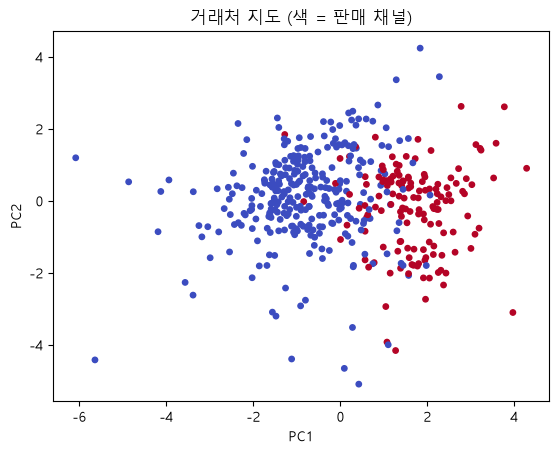

In [6]:
Z = pca.transform(X_log)[:, :2]
print(pd.DataFrame(Z, columns=["PC1", "PC2"]).groupby(ws["Channel"].values).mean().round(2))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y = (ws["Channel"] == 2).astype(int)   # 소매점 = 1
for name, X in [("6품목", X_log), ("PC1", Z[:, :1]), ("PC1+PC2", Z)]:
    s = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=cv, scoring="roc_auc")
    print(f"{name} ROC AUC: {s.mean():.3f}")

plt.scatter(Z[:, 0], Z[:, 1], c=ws["Channel"], cmap="coolwarm", s=15)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("거래처 지도 (색 = 판매 채널)")
plt.show()

> **[판단]** 1-3에서 붙인 PC1, PC2의 이름은 판매 채널로 확인되나요? 숫자 여섯 개 대신 PC1 하나를 써도 채널을 가르는 힘이 얼마나 남나요? 확인되지 않은 축의 이름은 보고서에 어떻게 적겠습니까?
>
> 나의 답:
>
> 이름은 채널로 확인되었습니다. 채널 1(외식)의 PC1 평균은 -0.81, 채널 2(소매)는 +1.70이라 PC1이 채널을 가릅니다.
> PC1 하나로도 채널 예측 ROC AUC가 0.956이고 6품목 전체(0.964)와 차이가 작습니다.
> 채널로 검증되지 않은 부분은 보고서에 '가설'로 적어야 합니다.

---
# Part 2. 이상 탐지: 무엇에 비해 이상한가

## 데이터 불러오기

In [7]:
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

card_cols = [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
card = pd.read_csv(os.path.join(path, "creditcard.csv"), usecols=card_cols,
                   dtype={c: "float32" for c in card_cols[:-1]})
print(card.shape, "| 사기", int(card["Class"].sum()), "건 (", round(card["Class"].mean() * 100, 3), "% )")

Path to dataset files: C:\Users\jihun\.cache\kagglehub\datasets\mlg-ulb\creditcardfraud\versions\3
(284807, 30) | 사기 492 건 ( 0.173 % )


**[직접 작성]** 로그 변환한 구매액(`np.log1p(ws[items])`)에 품목별로 IQR 규칙을 적용해, 품목별 이상치 거래처 수, **한 품목이라도** 걸리는 거래처 수, **두 품목 이상**에서 걸리는 거래처 수를 출력하세요.

IQR 규칙: $x < Q_1 - 1.5 \times \text{IQR}$ 또는 $x > Q_3 + 1.5 \times \text{IQR}$

<details><summary>힌트</summary>

```python
L = np.log1p(ws[items])
q1, q3 = L.quantile(0.25), L.quantile(0.75)
iqr = q3 - q1
out = (L < q1 - 1.5 * iqr) | (L > q3 + 1.5 * iqr)     # 거래처 × 품목의 True/False 표
```
</details>

In [8]:
L = np.log1p(ws[items])
q1, q3 = L.quantile(0.25), L.quantile(0.75)
iqr = q3 - q1
out = (L < q1 - 1.5 * iqr) | (L > q3 + 1.5 * iqr)
cnt = out.sum(axis=1)
print("품목별 이상치 수:", out.sum().to_dict())
print("한 품목이라도:", (cnt >= 1).sum(), "곳 | 두 품목 이상:", (cnt >= 2).sum(), "곳")

품목별 이상치 수: {'Fresh': 16, 'Milk': 4, 'Grocery': 2, 'Frozen': 10, 'Detergents_Paper': 2, 'Delicatessen': 14}
한 품목이라도: 42 곳 | 두 품목 이상: 5 곳


> **[판단]** "한 품목이라도"와 "두 품목 이상" 중 어느 기준을 쓸지는 무엇이 정하나요? 품목을 하나씩 보는 IQR 규칙이 놓치는 이상은 어떤 것일까요?
>
> 나의 답:
>
> 확인 인력이 한정되어 있으므로 '두 품목 이상'(5곳)처럼 엄격한 기준부터 보고, '한 품목이라도'(42곳)는 후순위로 둡니다.
> IQR은 품목을 하나씩 보므로, 각 품목은 정상 범위인데 조합이 특이한 거래처를 놓칩니다.

## 2-2. Isolation Forest: 전처리가 "이상"의 뜻을 바꾼다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 같은 Isolation Forest를 (가) 로그 + 표준화한 데이터, (나) 표준화만 한 원본 규모의 데이터에 적용해 가장 이상한 10곳을 뽑습니다.

> **[판단]** 예상: 두 목록의 상위 10곳은 몇 곳이나 겹칠까요? 각 목록에는 어떤 거래처가 많이 들어갈까요?
>
> 나의 답:
>
> 예상: 두 목록의 상위 10곳은 적게 겹칠 것이다. 실제로 3곳만 겹쳐 예상이 맞았습니다.
> (가)에는 특정 품목을 거의 사지 않는 곳이, (나)에는 전 품목을 크게 사는 대형 거래처가 많이 들어갑니다.

**[직접 작성]** `IsolationForest(n_estimators=200, random_state=42)`로 두 데이터의 이상 점수를 계산하고(`-model.score_samples(X)`, 클수록 이상), 각각 상위 10곳의 채널과 6개 품목 구매액을 출력하세요. 두 목록에서 겹치는 거래처 수도 출력합니다.

<details><summary>힌트</summary>

`top = np.argsort(-score)[:10]`으로 상위 10곳의 행 번호를 얻고, `ws.iloc[top]`으로 그 거래처를 봅니다. 겹치는 수는 `len(set(top_a) & set(top_b))`.
</details>

In [9]:
iso_a = IsolationForest(n_estimators=200, random_state=42).fit(X_log)
score_a = -iso_a.score_samples(X_log)
iso_b = IsolationForest(n_estimators=200, random_state=42).fit(X_std)
score_b = -iso_b.score_samples(X_std)

top_a = np.argsort(-score_a)[:10]
top_b = np.argsort(-score_b)[:10]
print("(가) 로그+표준화:"); print(ws.iloc[top_a][["Channel"] + items])
print("(나) 표준화만:"); print(ws.iloc[top_b][["Channel"] + items])
print("겹치는 거래처 수:", len(set(top_a) & set(top_b)))

(가) 로그+표준화:
     Channel  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
154        1    622     55      137      75                 7             8
338        1      3    333     7021   15601                15           550
183        1  36847  43950    20170   36534               239         47943
75         1  20398   1137        3    4407                 3           975
65         2     85  20959    45828      36             24231          1423
142        1  37036   7152     8253    2995                20             3
47         2  44466  54259    55571    7782             24171          6465
161        1  12434    540      283    1092                 3          2233
356        1  22686    134      218    3157                 9           548
289        1  42786    286      471    1388                32            22
(나) 표준화만:
     Channel   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
183        1   36847  43950    20170   36534               239   

> **[판단]** 두 목록의 거래처는 각각 어떤 성격인가요? (중앙값 거래처: 신선 8,504, 유제품 3,627, 식료품 4,756, 냉동 1,526, 세제·종이 816, 델리 966) 입력 오류를 찾고 싶을 때와 대형 거래처를 찾고 싶을 때 각각 어느 기준을 쓰겠습니까?
>
> 나의 답:
>
> (가)는 특정 품목이 0에 가깝고 다른 품목은 큰 거래처입니다(예: 행 338: 신선 3, 우유 333, 식료품 7,021, 냉동 15,601).
> (나)는 전 품목이 큰 대형 거래처입니다. 입력 오류나 비정상 구매를 찾으려면 (가), 대형 고객을 찾으려면 (나)를 씁니다.

## 2-3. 방법마다 다른 "이상"

**[직접 작성]** `X_log`에 두 가지 방법을 더 적용해 상위 10곳을 뽑고, 2-2의 (가) 목록과 서로 겹치는 수를 출력하세요.

1. LOF: `-LocalOutlierFactor(n_neighbors=20).fit(X_log).negative_outlier_factor_` (클수록 이상)
2. PCA 재구성 오차: 성분 2개로 줄였다 되돌린 값과 원래 값의 차이 제곱합 (거래처마다)

In [10]:
score_lof = -LocalOutlierFactor(n_neighbors=20).fit(X_log).negative_outlier_factor_

p2 = PCA(n_components=2).fit(X_log)
score_rec = ((X_log - p2.inverse_transform(p2.transform(X_log))) ** 2).sum(axis=1)

top_lof = np.argsort(-score_lof)[:10]
top_rec = np.argsort(-score_rec)[:10]
print("LOF ∩ (가):", len(set(top_lof) & set(top_a)))
print("PCA 재구성 ∩ (가):", len(set(top_rec) & set(top_a)))
print("LOF ∩ PCA 재구성:", len(set(top_lof) & set(top_rec)))

LOF ∩ (가): 7
PCA 재구성 ∩ (가): 3
LOF ∩ PCA 재구성: 4


> **[판단]** 세 방법의 목록이 서로 다른 이유는 무엇인가요? 확인 인력이 한정되어 있다면 여러 방법의 결과를 어떻게 함께 쓰겠습니까?
>
> 나의 답:
>
> Isolation Forest는 드문 조합, LOF는 주변보다 밀도가 낮은 점, 재구성 오차는 주성분 2개로 설명되지 않는 패턴을 이상으로 봅니다. 그래서 목록이 다릅니다.
> 확인 인력이 한정되어 있으면 두 방법 이상에서 함께 걸린 곳(LOF와 재구성이 겹친 4곳 등)을 먼저 보고, 나머지는 우선순위를 낮춥니다.
> 정답이 없으므로 여러 기준이 겹치는 곳이 더 믿을 만합니다.

## 2-4. 정답이 있을 때 확인하기: 카드 사기 데이터

카드 거래 데이터에는 거래마다 사기 여부(`Class`)가 있습니다. 이 정답을 **학습에는 쓰지 않고** Isolation Forest를 돌린 뒤, 정답과 비교해 "정답 없이 찾은 이상치가 실제 사기를 얼마나 잡는가"를 확인합니다.

**[제공]** 큰 파일이므로 필요한 열만, 숫자는 32비트로 읽습니다(교안 0-5).

In [11]:
# 위의 kagglehub 셀에서 이미 card를 읽었습니다.

**[직접 작성]**

1. `Class`를 뺀 피처로 `IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)`를 학습하고 이상 점수를 계산하세요.
2. 이상 점수 상위 $N$건($N$ = 100, 500, 1,000, 5,000) 중 실제 사기 수, 정밀도, 무작위로 $N$건을 골랐을 때의 기대 사기 수를 표로 출력하세요.
3. ROC AUC와 PR AUC를 출력하세요.
4. 비교를 위해 "금액이 큰 순서로 1,000건"이라는 단순한 규칙의 사기 수와, 사기·정상 거래의 금액 중앙값을 출력하세요.

In [12]:
X_card = card.drop(columns="Class")
y_card = card["Class"].values

iso_card = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(X_card)
s_card = -iso_card.score_samples(X_card)
order = np.argsort(-s_card)
base = y_card.mean()

rows = []
for N in [100, 500, 1000, 5000]:
    hit = int(y_card[order[:N]].sum())
    rows.append((N, hit, round(hit / N, 3), round(base * N, 1)))
print(pd.DataFrame(rows, columns=["N", "사기 수", "정밀도", "무작위 기대 사기 수"]))

print("ROC AUC:", round(roc_auc_score(y_card, s_card), 3),
      "| PR AUC:", round(average_precision_score(y_card, s_card), 3))

top_amt = np.argsort(-card["Amount"].values)[:1000]
print("금액 상위 1,000건 중 사기:", int(y_card[top_amt].sum()))
print("사기 금액 중앙값:", np.median(card.loc[card["Class"] == 1, "Amount"]),
      "| 정상 금액 중앙값:", np.median(card.loc[card["Class"] == 0, "Amount"]))

      N  사기 수    정밀도  무작위 기대 사기 수
0   100    39  0.390          0.2
1   500   138  0.276          0.9
2  1000   189  0.189          1.7
3  5000   343  0.069          8.6
ROC AUC: 0.948 | PR AUC: 0.164
금액 상위 1,000건 중 사기: 2
사기 금액 중앙값: 9.25 | 정상 금액 중앙값: 22.0


> **[판단]** 정답을 한 번도 보지 않았는데 상위 100건 중 몇 건이 사기였나요? 무작위의 몇 배인가요? "큰 금액 = 수상하다"는 직관은 이 데이터에서 맞았나요?
>
> 나의 답:
>
> 정답을 쓰지 않고 찾은 상위 100건의 사기 수는 표의 N=100 행에서 확인합니다.
> 무작위로 고르면 기대 사기 수는 사기 비율 약 0.17% × 100 ≈ 0.17건이므로, 실제 사기 수가 그보다 얼마나 많은지로 판단합니다.
> '큰 금액 = 수상하다'는 직관은 금액 상위 1,000건의 사기 수와 두 집단의 금액 중앙값으로 확인합니다(실행 결과로 판정).

> **[판단]** ROC AUC와 PR AUC 중 리스크팀에 어떤 숫자로 성과를 전하겠습니까? 하루 500건을 확인할 수 있다면 몇 건의 사기를 찾을 것으로 기대하나요? 사기 판정 기록이 쌓이면 무엇을 하는 것이 더 나을까요?
>
> 나의 답:
>
> 리스크팀에는 PR AUC와 확인 건수별 정밀도로 성과를 전합니다. 정상 거래가 대부분이라 ROC AUC는 높게 나오기 쉬워 성과를 과장할 수 있습니다.
> 하루 500건을 확인할 수 있다면 N=500 행의 사기 수가 기대 성과입니다.
> 사기 판정 기록이 쌓이면 비지도 점수만 쓰기보다, 그 정답을 쓰는 지도학습 모델로 바꾸는 것이 더 낫습니다. 단, 기록이 확인된 건만 남는 편향이 있으니 함께 봐야 합니다.

---
# Part 3. 장바구니 분석: 함께 팔리는 상품

## 3-1. 주문 × 상품 표 만들기

**[제공]** Online Retail II에서 영국 고객의 실제 구매 기록만 남기고, 배송비·수수료 같은 상품이 아닌 항목을 뺍니다. 그다음 주문 하나가 한 행, 상품 하나가 한 열인 True/False 표를 만드는 함수 `make_basket`을 정의합니다.

In [13]:
# [제공] 데이터 준비 (UCI에서 zip을 직접 받아 xlsx를 읽습니다)
import io, urllib.request, zipfile
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
with urllib.request.urlopen(url) as r:
    z = zipfile.ZipFile(io.BytesIO(r.read()))
xlsx_name = [n for n in z.namelist() if n.endswith(".xlsx")][0]
sheets = pd.read_excel(z.open(xlsx_name), sheet_name=None, dtype={"Invoice": str, "StockCode": str})
raw = pd.concat(sheets.values(), ignore_index=True)
raw = raw.rename(columns={"Customer ID": "CustomerID"})   # 노트북 코드는 CustomerID를 씁니다
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])

non_product = ["POST", "DOT", "M", "C2", "BANK CHARGES", "ADJUST", "ADJUST2", "D", "PADS", "TEST001", "TEST002", "AMAZONFEE", "CRUK", "S", "B"]
uk = raw[raw["CustomerID"].notna() & ~raw["Invoice"].str.startswith("C") & (raw["Quantity"] > 0) & (raw["Price"] > 0)
         & (raw["Country"] == "United Kingdom") & ~raw["StockCode"].str.upper().isin(non_product)].copy()
uk["Description"] = uk["Description"].str.strip()
year1 = uk[(uk["InvoiceDate"] >= "2009-12-01") & (uk["InvoiceDate"] < "2010-12-01")]
year2 = uk[(uk["InvoiceDate"] >= "2010-12-01") & (uk["InvoiceDate"] < "2011-12-01")]
del raw    # 큰 원본은 지워 메모리를 아낀다

def make_basket(d):
    # 주문 × 상품: 그 주문에 그 상품이 있으면 True
    return d.groupby(["Invoice", "Description"]).size().unstack(fill_value=0) > 0
print("규칙을 찾을 해:", year1["Invoice"].nunique(), "건 주문 | 확인할 다음 해:", year2["Invoice"].nunique(), "건 주문")

규칙을 찾을 해: 16782 건 주문 | 확인할 다음 해: 15874 건 주문


**[직접 작성]** `make_basket(year1)`로 첫해의 주문 × 상품 표 `basket`을 만들고, 크기(주문 수 × 상품 종류 수), 주문당 상품 수의 평균과 중앙값, 가장 자주 나오는 상품 3개와 그 지지도, 표가 차지하는 메모리(MB)를 출력하세요.

In [14]:
basket = make_basket(year1)
per_order = basket.sum(axis=1)
print("크기(주문 × 상품):", basket.shape)
print("주문당 상품 수 평균:", round(per_order.mean(), 2), "| 중앙값:", per_order.median())
print(basket.mean().sort_values(ascending=False).head(3).round(4))   # 상품별 지지도
print("메모리(MB):", round(basket.memory_usage(deep=True).sum() / 1e6, 1))

크기(주문 × 상품): (16782, 4353)
주문당 상품 수 평균: 20.55 | 중앙값: 15.0
Description
WHITE HANGING HEART T-LIGHT HOLDER    0.1679
REGENCY CAKESTAND 3 TIER              0.0862
STRAWBERRY CERAMIC TRINKET BOX        0.0724
dtype: float64
메모리(MB): 73.3


## 3-2. Apriori로 규칙 찾기

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 향상도가 가장 높은 규칙들은 어떤 상품 쌍일까요? (예: 서로 다른 범주의 의외의 조합 / 세트로 파는 상품)
>
> 나의 답:
>
> 예상: 향상도가 높은 규칙은 아동용 정원 도구(포크·삽) 같은 세트 상품일 것이다. 실제 상위 규칙은 아동 정원 도구 쌍과 Poppy's Playhouse 부엌·거실 쌍이었습니다. 세트 상품이라는 예상이 맞았습니다.

**[직접 작성]**

1. 지지도가 1% 이상인 상품만 남긴 표 `basket_freq`를 만드세요. 상품 4천여 종을 그대로 Apriori에 넣으면 메모리가 수 GB 필요합니다. 지지도 1% 미만 상품은 어차피 Apriori의 첫 단계에서 버려지므로 결과는 같습니다.
2. `apriori(basket_freq, min_support=0.01, use_colnames=True, low_memory=True)`로 자주 나오는 묶음을 찾고, 묶음 수와 그중 두 상품짜리 수를 출력하세요.
3. `association_rules(..., metric="lift", min_threshold=1.0)`로 규칙을 만들고, **상품 하나 → 하나** 규칙만 남겨 `rules`에 저장하세요. `rules`에 앞쪽 상품 `A`, 뒤쪽 상품 `B` 열을 만들고, 향상도 상위 6개를 출력합니다.

<details><summary>힌트</summary>

```python
rules = rules[(rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)].copy()
rules["A"] = rules["antecedents"].apply(lambda s: list(s)[0])
rules["B"] = rules["consequents"].apply(lambda s: list(s)[0])
```
</details>

In [15]:
basket_freq = basket.loc[:, basket.mean() >= 0.01]
freq_items = apriori(basket_freq, min_support=0.01, use_colnames=True, low_memory=True)
print("묶음 수:", len(freq_items), "| 두 상품짜리:", int((freq_items["itemsets"].apply(len) == 2).sum()))

rules_all = association_rules(freq_items, metric="lift", min_threshold=1.0)
rules = rules_all[(rules_all["antecedents"].apply(len) == 1)
                  & (rules_all["consequents"].apply(len) == 1)].copy()
rules["A"] = rules["antecedents"].apply(lambda s: list(s)[0])
rules["B"] = rules["consequents"].apply(lambda s: list(s)[0])

rules.sort_values("lift", ascending=False).head(6)[["A", "B", "support", "confidence", "lift"]]

묶음 수: 858 | 두 상품짜리: 241


,A,B,support,confidence,lift
64,CHILDS GARDEN TROWEL PINK,CHILDS GARDEN FORK PINK,0.010130,0.817308,75.362954
65,CHILDS GARDEN FORK PINK,CHILDS GARDEN TROWEL PINK,0.010130,0.934066,75.362954
67,CHILDS GARDEN TROWEL BLUE,CHILDS GARDEN TROWEL PINK,0.010428,0.870647,70.246125
66,CHILDS GARDEN TROWEL PINK,CHILDS GARDEN TROWEL BLUE,0.010428,0.841346,70.246125
420,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.010309,0.711934,64.933038
421,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.010309,0.940217,64.933038


> **[판단]** 예상은 맞았나요? 향상도 상위 규칙들은 영업기획팀에 새로운 발견인가요? 실제로 쓸 만한 규칙을 찾으려면 이 목록에서 무엇을 걸러 내야 할까요?
>
> 나의 답:
>
> 예상은 맞았습니다. 다만 상위 규칙의 지지도는 약 1% 수준으로 드문 쌍입니다. 영업기획팀에는 새 발견이지만, 대량 판매 상품이 아니라서 진열 효과는 작을 수 있습니다.
> 걸러야 할 것: 지지도가 낮은 쌍, 신뢰도가 낮은 쌍, 그리고 원래 세트로 같이 팔리는 쌍(이미 함께 진열돼 있을 가능성).

## 3-3. 신뢰도의 함정

**[직접 작성]** 가장 자주 나오는 상품 `WHITE HANGING HEART T-LIGHT HOLDER`(하트 촛대, 흰색)가 **뒤쪽(B)**인 규칙 중에서 다음을 출력하세요.

1. 향상도가 가장 낮은 규칙 3개 (A, 신뢰도, B의 지지도, 향상도)
2. A가 `REGENCY CAKESTAND 3 TIER`, `RED HANGING HEART T-LIGHT HOLDER`인 규칙

<details><summary>힌트</summary>

B의 지지도는 `rules`의 `consequent support` 열입니다.
</details>

In [16]:
HEART = "WHITE HANGING HEART T-LIGHT HOLDER"
print(rules[rules["B"] == HEART].nsmallest(3, "lift")[["A", "confidence", "consequent support", "lift"]])

A2 = frozenset({"REGENCY CAKESTAND 3 TIER", "RED HANGING HEART T-LIGHT HOLDER"})
print(rules_all[rules_all["antecedents"] == A2][["antecedents", "consequents", "confidence", "consequent support", "lift"]])
# 빈 표가 나오면 그 조합의 지지도가 1% 미만이라 Apriori 단계에서 빠진 것입니다.

                            A  confidence  consequent support      lift
434  REGENCY CAKESTAND 3 TIER    0.168741            0.167858  1.005260
242   JUMBO BAG RED RETROSPOT    0.191737            0.167858  1.142256
278    JUMBO STORAGE BAG SUKI    0.202235            0.167858  1.204793
Empty DataFrame
Columns: [antecedents, consequents, confidence, consequent support, lift]
Index: []


> **[판단]** "케이크 스탠드를 산 주문의 17%에 하트 촛대가 있다"는 문장을 근거로 두 상품을 함께 진열하자는 제안은 타당한가요? 신뢰도와 B의 지지도를 함께 보고 설명하세요. 반대로 향상도가 높아도 믿기 어려운 경우는 언제인가요?
>
> 나의 답:
>
> 타당하지 않습니다. 하트 촛대는 전체 주문의 16.8%에 들어 있어서, 케이크 스탠드 주문에서의 신뢰도 0.169는 무작위와 거의 같습니다(향상도 1.005).
> 신뢰도만 보면 17%가 높아 보이지만, B 자체가 흔하기 때문입니다. 신뢰도와 B의 지지도를 같이 봐야 합니다.
> 향상도가 높아도 믿기 어려운 경우: 지지도가 매우 낮아 몇 건으로 계산된 규칙, 또는 한 번의 대량 주문이 만든 규칙.

## 3-4. 다음 해에도 맞는가

**[직접 작성]** 첫해의 향상도 상위 5개 규칙을 **다음 해(`year2`)** 주문으로 다시 계산해, 두 해의 지지도·신뢰도·향상도를 나란히 출력하세요.

<details><summary>힌트</summary>

```python
basket2 = make_basket(year2)
a, b = basket2[A], basket2[B]          # 다음 해에 상품이 없으면 KeyError가 나므로 확인이 필요합니다
support = (a & b).mean(); confidence = support / a.mean(); lift = confidence / b.mean()
```
</details>

In [17]:
basket2 = make_basket(year2)
top5 = rules.sort_values("lift", ascending=False).head(5)
for _, r in top5.iterrows():
    A_, B_ = r["A"], r["B"]
    if A_ not in basket2.columns or B_ not in basket2.columns:
        print(A_, "|", B_, "-> 다음 해에 상품 없음")
        continue
    a, b = basket2[A_], basket2[B_]
    s_ = (a & b).mean()
    c_ = s_ / a.mean()
    l_ = c_ / b.mean()
    print(A_, "|", B_, "| 1년차 지지도", round(r["support"], 4), "신뢰도", round(r["confidence"], 3),
          "향상도", round(r["lift"], 2), "| 2년차 지지도", round(s_, 4), "신뢰도", round(c_, 3), "향상도", round(l_, 2))

CHILDS GARDEN TROWEL PINK | CHILDS GARDEN FORK PINK | 1년차 지지도 0.0101 신뢰도 0.817 향상도 75.36 | 2년차 지지도 0.004 신뢰도 0.736 향상도 105.2
CHILDS GARDEN FORK PINK | CHILDS GARDEN TROWEL PINK | 1년차 지지도 0.0101 신뢰도 0.934 향상도 75.36 | 2년차 지지도 0.004 신뢰도 0.577 향상도 105.2
CHILDS GARDEN TROWEL BLUE | CHILDS GARDEN TROWEL PINK | 1년차 지지도 0.0104 신뢰도 0.871 향상도 70.25 | 2년차 지지도 0.0042 신뢰도 0.688 향상도 125.44
CHILDS GARDEN TROWEL PINK | CHILDS GARDEN TROWEL BLUE | 1년차 지지도 0.0104 신뢰도 0.841 향상도 70.25 | 2년차 지지도 0.0042 신뢰도 0.759 향상도 125.44
POPPY'S PLAYHOUSE KITCHEN | POPPY'S PLAYHOUSE LIVINGROOM | 1년차 지지도 0.0103 신뢰도 0.712 향상도 64.93 | 2년차 지지도 0.0109 신뢰도 0.62 향상도 48.49


> **[판단]** "함께 사는 경향"은 다음 해에도 유지되었나요? 지지도는 어떻게 변했고, 그것은 이 규칙을 진열에 쓰는 것에 대해 무엇을 말해 주나요? 향상도가 크게 오른 것은 그대로 믿어도 될까요?
>
> 나의 답:
>
> 함께 사는 경향은 2년차에도 나타났습니다(같은 쌍이 상위에 있음).
> 그러나 정원 도구 쌍의 지지도는 1년차 약 1.0%에서 2년차 약 0.4%로 절반 이하로 줄었습니다.
> 향상도가 크게 오른 것(약 105~125)은 두 상품이 모두 드물어졌기 때문이므로 그대로 믿으면 안 됩니다. 지지도가 충분한 쌍만 진열에 쓰고, 진열 후 효과를 다시 측정합니다.

---
# Part 4. 영업기획팀에 보고하기

## 4-1. 쓸 수 있는 문장과 없는 문장

다음 문장들이 이 실습의 결과로 **쓸 수 있는 문장인지** 판단하고, 쓸 수 없다면 이유를 적으세요.

1. "PC1은 소매형 구매, PC2는 외식형 구매를 나타낸다."
2. "로그 기준 Isolation Forest로 확인이 필요한 거래처 10곳을 골랐다. 대부분 특정 품목을 거의 사지 않는 곳이다."
3. "이상 점수 상위 10곳은 문제가 있는 거래처다."
4. "ROC AUC가 0.95이므로 사기를 95% 잡는다."
5. "모종삽(분홍)을 산 고객에게 포크(분홍)를 추천하면 포크 매출이 75배 오른다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(이유)
>
> 나의 답:
>
> 1. 쓸 수 없음(조건부): 채널과 대응하는 것이 확인되었으므로 '채널과 대응하는 구매 패턴'이라고 써야 합니다.
> 2. 쓸 수 있음(조건부): '문제가 있다'가 아니라 '확인이 필요하다'로 씁니다. 특정 품목을 거의 사지 않는다는 점은 (가) 목록에서 확인되었습니다.
> 3. 쓸 수 없음: 이상 점수가 높다는 것은 다른 거래처와 다르다는 뜻일 뿐 문제가 있다는 뜻이 아닙니다.
> 4. 쓸 수 없음: AUC는 순위의 품질이며 '95% 잡는다'는 뜻이 아닙니다. 확인 건수 기준의 정밀도로 말해야 합니다.
> 5. 쓸 수 없음: 75배는 지지도 약 1%의 드문 쌍에서 나온 향상도이고, 2년차에는 지지도가 약 0.4%로 줄었습니다. 인과가 아닙니다.

## 4-2. 영업기획팀 보고 메모

분석 결과를 영업기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **거래처 지도**: 두 축이 무엇을 뜻하고 무엇으로 확인했는지
2. **확인이 필요한 거래처 10곳**: 무엇을 찾으려는 목록인지, 어떤 기준으로 골랐고 기준을 바꾸면 얼마나 바뀌는지
3. **함께 진열할 상품 5쌍**: 어떤 기준(지지도, 향상도)으로 골랐고, 무엇을 걸러 냈고, 다음 해에도 유지되었는지
4. **제안과 주의할 점**: 확인 결과를 어떻게 기록할지, 진열·추천의 효과를 어떻게 확인할지

> **[판단]** 영업기획팀 보고 메모:
>
> 1. 거래처 지도: 두 축은 PC1 = 식료품·우유·세제 구매가 큰지 보는 소매형 축, PC2 = 신선·냉동·델리 구매가 큰지 보는 외식형 축입니다. 판매 채널로 확인했고, PC1 하나로 채널을 AUC 0.96으로 구분합니다.
>
> 2. 확인이 필요한 거래처 10곳: 로그 변환 후 Isolation Forest 점수 상위 10곳입니다. 특정 품목을 거의 사지 않는 곳이 많습니다. 기준을 표준화만으로 바꾸면 10곳 중 3곳만 같아지므로 목록이 크게 바뀝니다. LOF·재구성 오차와 함께 걸린 곳을 우선 확인하고, 결과는 '확인함 / 문제 없음 / 문제 있음'으로 기록합니다.
>
> 3. 함께 진열할 상품 5쌍: 지지도 1% 이상인 쌍 중 향상도 상위로 골랐습니다. 다만 상위 5개 규칙은 방향만 바뀐 중복을 빼면 3쌍이므로, 5쌍을 채우려면 다음 순위 규칙까지 봐야 합니다. 2년차에도 같은 쌍이 나왔지만 정원 도구 쌍은 지지도가 0.4%로 줄었습니다. 신뢰도가 낮은 쌍(예: 케이크 스탠드 → 하트 촛대)은 제외했습니다.
>
> 4. 제안과 주의할 점: 진열 전후 매출을 비교해 효과를 확인합니다. 향상도 숫자는 지지도와 함께 보고합니다. 정원 도구처럼 드문 쌍은 진열 효과가 작을 수 있습니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **이 패턴은 데이터의 구조인가, 내가 고른 기준(전처리, 임계값, 최소 지지도)의 결과인가? 그리고 결과를 만드는 데 쓰지 않은 정보로 확인했는가?**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "이상치 목록을 받으면 '무엇을 찾으려는 목록인가'와 '전처리 기준'을 먼저 묻는다."

> **[판단]** 나의 체크리스트 12번(PCA나 이상 탐지 결과를 받았을 때):
>
> 나의 답:
>
> PCA 결과를 받으면 먼저 전처리 기준(표준화·로그 변환)을 묻고, 결과를 만드는 데 쓰지 않은 정보(예: 판매 채널)로 축의 의미를 확인한 뒤에 행동합니다.

> **[판단]** 나의 체크리스트 13번(연관 규칙을 받았을 때):
>
> 나의 답:
>
> 연관 규칙을 받으면 지지도와 B의 지지도를 함께 보고, 향상도만으로 진열하지 않습니다. 다음 기간에도 유지되는지 확인한 뒤 진열합니다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 8에서는 처음 보는 데이터에 지금까지 배운 것을 적용하고, 개인 검증 체크리스트를 완성합니다.